<a href="https://www.kaggle.com/code/abrandonwang/clotho-explore?scriptVersionId=363633952" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
!pip install -q py7zr
import torch
import glob
import pandas as pd
import py7zr, os
from IPython.display import Audio, HTML, display
import html
import librosa, librosa.display
import matplotlib.pyplot as plt
import numpy as np

archives = glob.glob("/kaggle/input/**/*.7z", recursive=True)
print(archives)

['/kaggle/input/datasets/afonsolopodecarvalho/clothov21/clotho_audio_evaluation.7z', '/kaggle/input/datasets/afonsolopodecarvalho/clothov21/clotho_audio_development.7z', '/kaggle/input/datasets/afonsolopodecarvalho/clothov21/clotho_audio_validation.7z']


In [2]:
!pip install -q py7zr
!wget -q "https://zenodo.org/records/4783391/files/clotho_captions_development.csv?download=1" -O /kaggle/working/captions_dev.csv
caps = pd.read_csv("/kaggle/working/captions_dev.csv")
caps.head()

,file_name,caption_1,caption_2,caption_3,caption_4,caption_5
0,Distorted AM Radio noise.wav,A muddled noise of broken channel of the TV,A television blares the rhythm of a static TV.,Loud television static dips in and out of focus,The loud buzz of static constantly changes pit...,heavy static and the beginnings of a signal on...
1,Paper_Parchment_Rustling.wav,A person is turning a map over and over.,A person is very carefully rapping a gift for ...,A person is very carefully wrapping a gift for...,"He sighed as he turned the pages of the book, ...","papers are being turned, stopped, then turned ..."
2,03 Whales Slowing Down.wav,Several barnyard animals mooing in a barn whil...,"The vocalization of several whales, along with...","Underwater, large numbers of shrimp clicking a...",Whales sing to one another over the flowing wa...,wales sing to one another with water flowing i...
3,Rope tied to boat in port.wav,An office chair is squeaking as someone bends ...,Popping and squeaking gradually tapers off to ...,Someone is opening a creaky door slowly while ...,Squeaking and popping followed by gradual popp...,an office chair is squeaking as someone leans ...
4,carpenter bee.wav,A flying bee is buzzing loudly around an objec...,An annoying fly is buzzing loudly and consiste...,An insect buzzing in the foreground as birds c...,"An insect trapped in a spider web struggles, b...","Outdoors, insect trapped in a spider web and t..."


In [3]:
dev = [a for a in archives if "development" in a][0] # i assume is going through our dataset and looking for the word development in each data row?
with py7zr.SevenZipFile(dev) as z:
    names = [n for n in z.getnames() if n.endswith(".wav")][:20]
with py7zr.SevenZipFile(dev) as z:
    z.extract(path = "/kaggle/working/sample", targets = names)

wavs = sorted(glob.glob("/kaggle/working/sample/**/*.wav", recursive = True))
print(len(wavs), "files")

20 files


In [4]:
for path in wavs[:3]:
    name = os.path.basename(path)
    row = caps[caps.file_name == name]
    lines = [f"<b>{html.escape(name)}</b>"]
    if len(row):
        for i in range(1, 6):
            cap = html.escape(str(row.iloc[0][f"caption_{i}"]))
            lines.append(f"&nbsp;&nbsp;{i}. {cap}")
    else:
        lines.append("&nbsp;&nbsp;(no captions found)")
    player = Audio(path)._repr_html_()
    display(HTML("<br>".join(lines) + "<br>" + player + "<hr>"))


sample rate:  44100 | length: 17.4 s


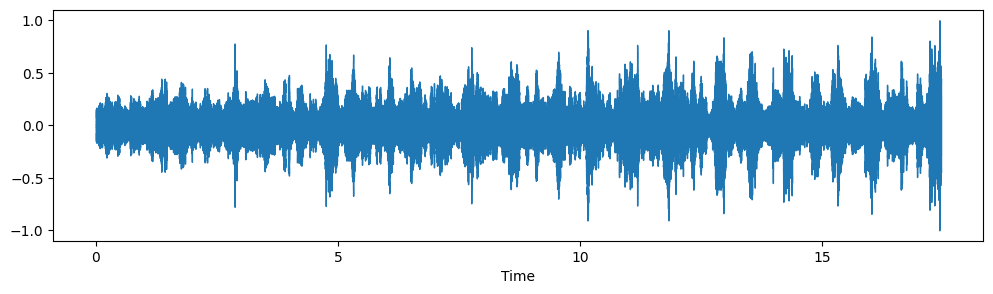

In [5]:
y, sr = librosa.load(wavs[0], sr = None)
print("sample rate: ", sr, "| length:", round(len(y) / sr, 1), "s")

plt.figure(figsize = (12, 3))
librosa.display.waveshow(y, sr = sr)
plt.show()

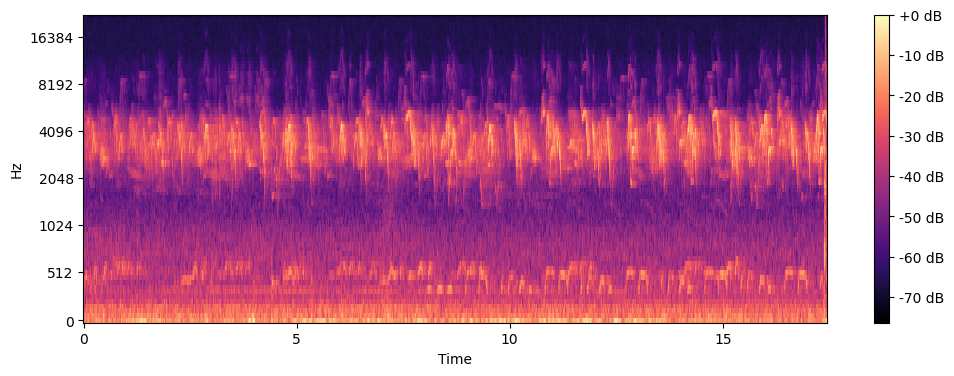

In [6]:
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=80)
S_db = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.show()